<font color="black"><h1><b>Pitcher Arsenal Comparison</b></h1></font>

# Introduction

This script compares pitchers based on the similarity of their pitch arsenals and their pitching speeds. We use Euclidean distance of pitch arsenals to compare pitchers' arsenals. This can answer the question: which pitchers in the MLB have the most similar pitching style. Rather than comparing the movement of the pitches, we are comparing the rate at which pitchers throw different pitch types and the speed at which they throw these pitches.

Additionally, this script creates a multi-layer back-prop model and trains it on the data with the output variable being the type of pitch thrown. The goal of the model is to create and train a model that can accurately predict the type of pitch that was thrown based off of things like pitch velocity, horizontal movement, vertical movement, expected whiff percent, oba, etc. The larger idea is that the model could be used on future data, and for any given pitch in the mlb it could classify the type of pitch that was thrown only based on the parameters that it was trained with.

# Data Setup

In [1]:
# !pip install plotly
import plotly.graph_objects as go
import matplotlib as mpl

# !pip install tensorflow
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, callbacks
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# !pip install adjustText
from adjustText import adjust_text

from keras import backend as K

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# dataset
baseball = pd.read_csv('../data/derived/data24-26.csv', on_bad_lines='skip')

pitch_names = {
    "FF": "Four-Seam Fastball", "SL": "Slider", "ST": "Sweeper", "SI": "Sinker",
    "CH": "Changeup", "CU": "Curveball", "FC": "Cutter", "FS": "Split Finger",
    "KN": "Knuckleball", "SV": "Slurve", "FO": "Forkball",
}

# Fixed order = every pitch type always lives in the same vector position
PITCH_ORDER = list(pitch_names.keys())
PITCH_LABELS = [pitch_names[p] for p in PITCH_ORDER]

PITCH_COLORS = {
    'FF': '#d22d49', 'SI': '#fe9d00', 'FC': '#933f2c', 'SL': '#eee716', 'ST': '#ddb33a',
    'SV': '#93afd4', 'CU': '#00d1ed', 'CH': '#1dbe3a', 'FS': '#3bacac', 'FO': '#55ccab',
    'KN': '#3c44cd'}

baseball['pitch_name'] = baseball['pitch_type'].replace(pitch_names)

def movement_plot(data, name, year):
    df = data[(data['name'] == name)& (data['year'] == year)].sort_values('pitch_usage', ascending=False)
    if df.empty:
        raise ValueError(f'No rows for {name} in {year}')
    hand = df['hand'].iloc[0]

    # pitcher_break_x is unsigned. league_break_x is signed (< 0 = arm side, > 0 = glove side) and
    # diff_x = pitcher's break toward the league direction minus |league_break_x|, so
    # |league_break_x| + diff_x < 0 means this pitch breaks the opposite way from the league average.
    league_arm = np.where(df['league_break_x'] < 0, 1, -1)
    league_arm = np.where(df['league_break_x'].isna(), 1, league_arm)  # forkballs has no league avg: arm side
    toward_league = df['league_break_x'].abs() + df['diff_x']
    same_side = np.where(toward_league.isna() | (toward_league >= 0), 1, -1)
    # Pitcher's view: 1B on the left, 3B on the right, so a RHP's arm side is +x and a LHP's is -x.
    # Determines correct side for pitch break
    x = df['pitcher_break_x'] * league_arm * same_side * (1 if hand == 'R' else -1)
    z = df['pitcher_break_z_induced']

    fig, ax = plt.subplots(figsize=(7, 7))
    for r in [6, 12, 18, 24]:
        ax.add_patch(plt.Circle((0, 0), r, fill=False, color='gray',ls='-', lw=0.8, alpha=0.6))
    ax.axhline(0, color='gray', lw=0.8)
    ax.axvline(0, color='gray', lw=0.8)

    for (_, row), xi, zi in zip(df.iterrows(), x, z):
        ax.scatter(xi, zi, s=row['pitch_usage'] * 40, color=PITCH_COLORS.get(row['pitch_type'], 'gray'),
                   alpha=0.8, edgecolor='black', zorder=3,
                   label=f"{row['pitch_type']}  {row['pitch_usage']:.0f}%  {row['avg_speed']:.1f} mph ({xi}, {zi})")

    ax.set_xlim(-26, 26)
    ax.set_ylim(-26, 26)
    ax.set_aspect('equal')
    ax.set_xlabel('Horizontal break (in)   ← 1B  |  3B →')
    ax.set_ylabel('Induced vertical break (in)')
    ax.set_title(f'{name} ({hand}HP) – {year} Movement Profile', fontsize=10)
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), markerscale=0.4, labelspacing=1.2, frameon=False)
    plt.tight_layout()
    return fig, ax


# Evaluating the similarity of pitchers

Most similar pairs:
          pitcher_a        pitcher_b  distance
0    Brebbia, John     Jiménez, Joe  4.506368
1   Hudson, Daniel    Ginkel, Kevin  4.809428
2  Fairbanks, Pete  Leasure, Jordan  5.887422
3     Jiménez, Joe    Imai, Tatsuya  6.063046
4      Díaz, Edwin  Leasure, Jordan  6.472085

Least similar pairs:
             pitcher_a        pitcher_b    distance
119315  Kahnle, Tommy  Clase, Emmanuel  120.357198
119314  Kahnle, Tommy    Rogers, Tyler  120.313179
119313  Kahnle, Tommy      Hader, Josh  115.767913
119312  Rogers, Tyler  Clase, Emmanuel  114.749271
119311  Rogers, Tyler  Kopech, Michael  113.474818


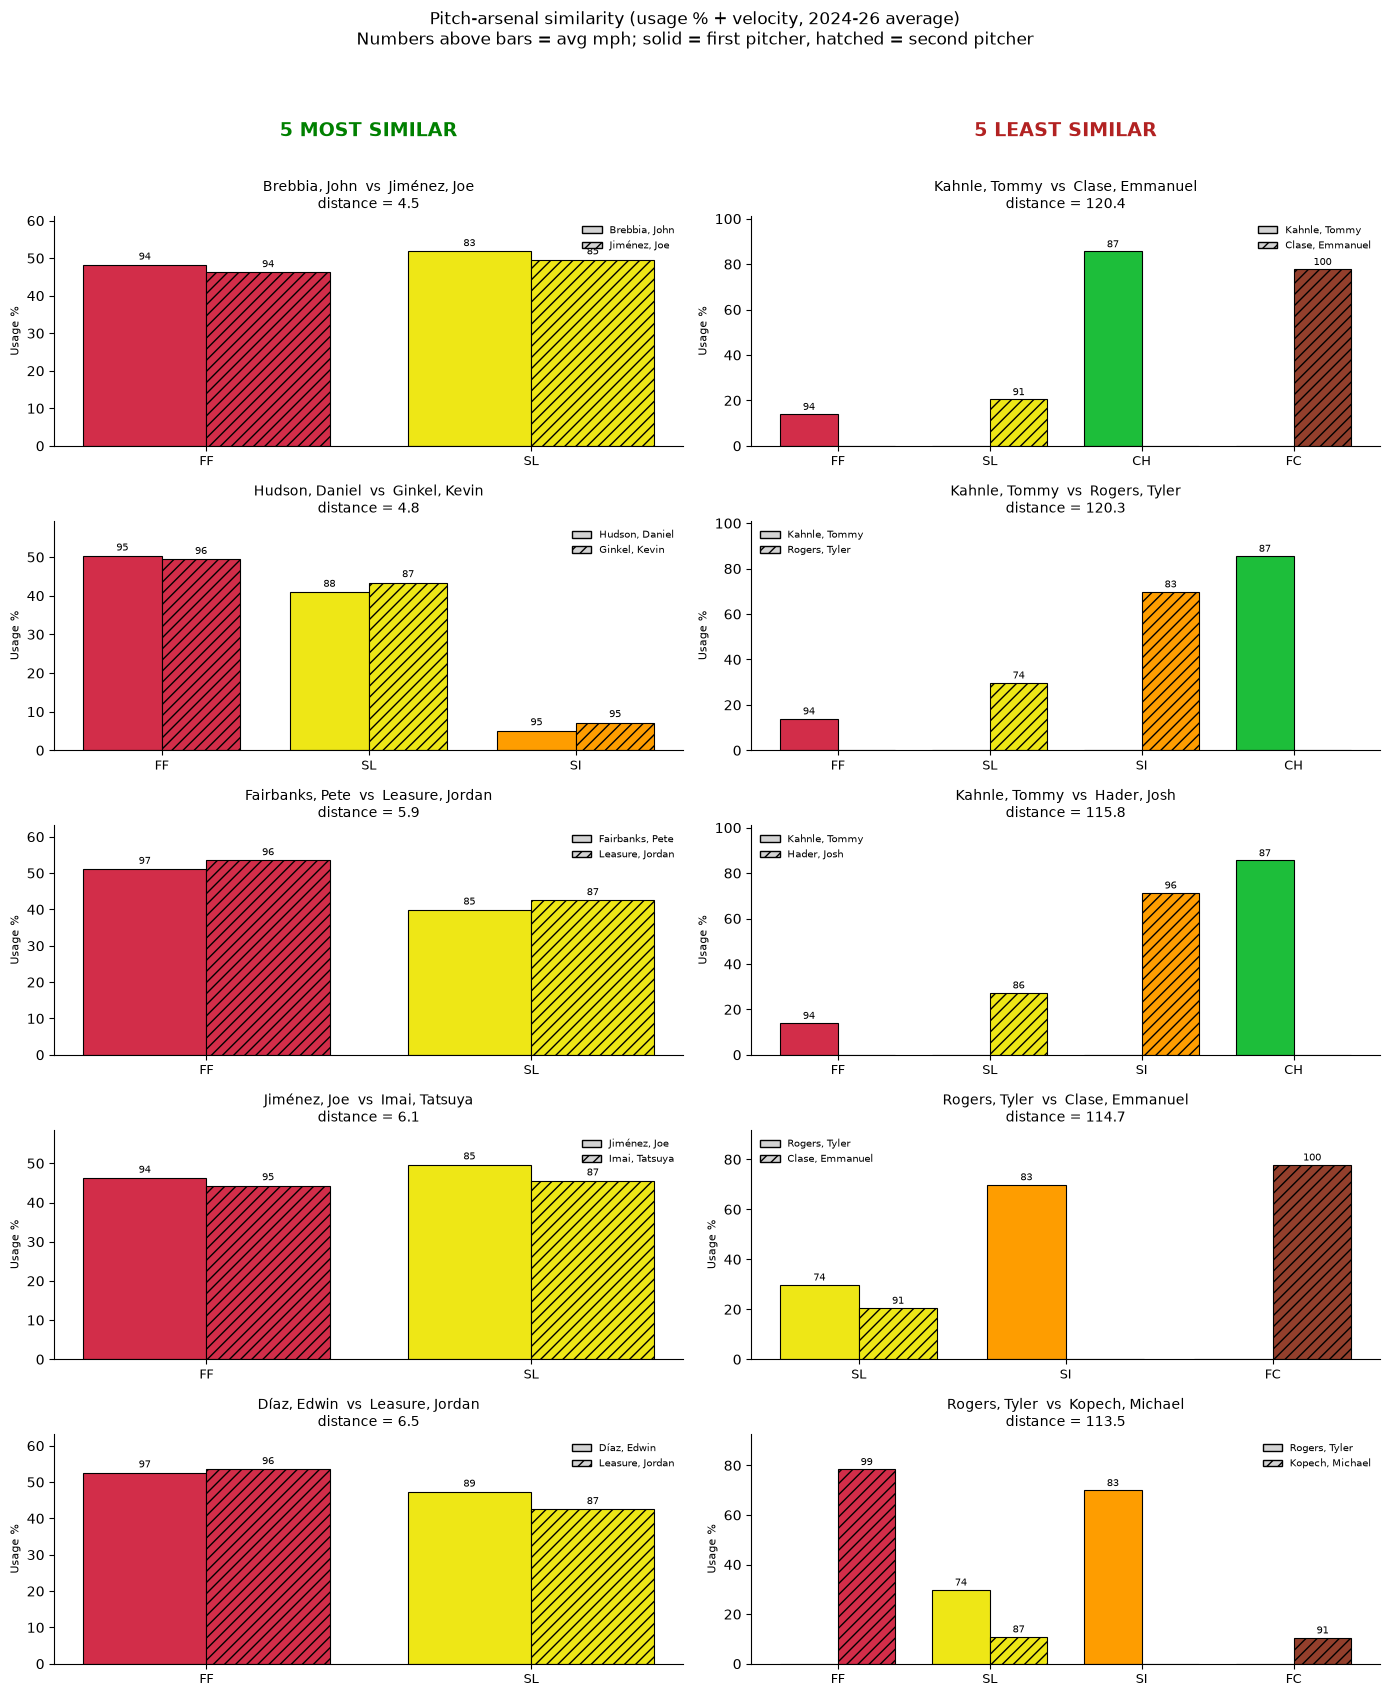

In [2]:
# PART 1: one usage vector per pitcher-year
# ---------------------------------------------------------------------------
# Index by 'id' (unique per pitcher) and keep 'name' alongside for display.
usage_by_year = (
    baseball
    .pivot_table(index=['id', 'name', 'year'], columns='pitch_type',
                 values='pitch_usage', aggfunc='sum')
    .reindex(columns=PITCH_ORDER)
    .fillna(0)               # no row for a pitch -> 0% usage
)

# Raw velocities by year (NaN where the pitch wasn't thrown; filled later)
speed_by_year = (
    baseball
    .pivot_table(index=['id', 'name', 'year'], columns='pitch_type',
                 values='avg_speed', aggfunc='mean')
    .reindex(columns=PITCH_ORDER)
)

# Usage:  usage_by_year.loc[(id, name, year)].values -> 11-element vector
# e.g. usage_by_year.xs('Webb, Logan', level='name')  -> all of Webb's seasons


def yearly_arsenal_change(name):
    """Euclidean distance between a pitcher's consecutive seasons' usage vectors."""
    seasons = usage_by_year.xs(name, level='name').droplevel('id')
    years = seasons.index.tolist()
    return {f"{a}->{b}": float(np.linalg.norm(seasons.loc[b] - seasons.loc[a]))
            for a, b in zip(years[:-1], years[1:])}

# PART 2: one averaged usage vector per pitcher (across seasons they pitched)

usage_avg = usage_by_year.groupby(level=['id', 'name']).mean()
speed_avg = speed_by_year.groupby(level=['id', 'name']).mean()   

# PART 3: usage + velocity vector (22 dims: 11 usage, then 11 velocities)

def build_combined_vectors(usage, speed, velocity_weight=5.0):
    """
    Append velocities to usage, same pitch order, 0 where a pitch isn't thrown.

    Usage is in percentage points (0-100). Raw velocity is ~80-95 mph, which
    would swamp usage in a Euclidean distance, so velocity needs rescaling:

    Each pitch type's velocity is converted to a z-score vs. the league
    (how many SDs faster/slower than the average pitcher's version of that
    pitch), then multiplied by velocity_weight. 0 = league-average speed,
    so a pitch that isn't thrown gets a neutral 0 instead of an artificial
    "0 mph" penalty.

    velocity_weight: how much a velocity difference matters relative to usage.
        With 'zscore', weight=5 means 1 SD of velocity (~2-3 mph) counts as
        much as a 5-percentage-point difference in usage."""
    
    mu = speed.mean()
    sd = speed.std().fillna(1).replace(0, 1)   # rare pitches (KN) can have 0/1 samples
    vel = ((speed - mu) / sd * velocity_weight).fillna(0)

    vel.columns = [f"{c}_velo" for c in vel.columns]
    return pd.concat([usage, vel], axis=1)

combined_avg = build_combined_vectors(usage_avg, speed_avg)

# Euclidean distance between every pair of pitchers

def pairwise_distances(vectors: pd.DataFrame) -> pd.DataFrame:
    """Return all unique pitcher pairs with their Euclidean distance."""
    X = vectors.values
    names = vectors.index.get_level_values('name').to_numpy()
    ids = vectors.index.get_level_values('id').to_numpy()
    i, j = np.triu_indices(len(X), k=1)               # each pair once, no self-pairs
    dist = np.linalg.norm(X[i] - X[j], axis=1)
    return (pd.DataFrame({'id_a': ids[i], 'pitcher_a': names[i],
                          'id_b': ids[j], 'pitcher_b': names[j],
                          'distance': dist})
            .sort_values('distance').reset_index(drop=True))


pairs = pairwise_distances(combined_avg)
most_similar = pairs.head(5)
least_similar = pairs.tail(5).iloc[::-1]   # least similar first

print("Most similar pairs:\n", most_similar[['pitcher_a', 'pitcher_b', 'distance']])
print("\nLeast similar pairs:\n", least_similar[['pitcher_a', 'pitcher_b', 'distance']])

# Visualization

def plot_pair(ax, row, usage, speed):
    """
    Grouped bars of pitch usage for two pitchers, colored by pitch type.
    Both pitchers share a pitch's color, so they are told apart by texture:
    pitcher A = solid bar, pitcher B = hatched bar. mph is labelled above bars.
    """
    from matplotlib.patches import Patch

    a = usage.xs(row.id_a, level='id').iloc[0]
    b = usage.xs(row.id_b, level='id').iloc[0]
    sa = speed.xs(row.id_a, level='id').iloc[0]
    sb = speed.xs(row.id_b, level='id').iloc[0]

    keep = [p for p in PITCH_ORDER if a[p] > 0 or b[p] > 0]   # pitches either throws
    x = np.arange(len(keep))
    w = 0.38
    colors = [PITCH_COLORS[p] for p in keep]

    ax.bar(x - w / 2, [a[p] for p in keep], w, color=colors,
           edgecolor='black', linewidth=0.8)
    ax.bar(x + w / 2, [b[p] for p in keep], w, color=colors,
           edgecolor='black', linewidth=0.8, hatch='///')

    for xi, p in zip(x, keep):
        for off, u, s_ in ((-w / 2, a[p], sa[p]), (w / 2, b[p], sb[p])):
            if u > 0:
                ax.text(xi + off, u + 0.8, f"{s_:.0f}", ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(keep, fontsize=9)
    ax.set_ylim(0, max(a.max(), b.max()) * 1.18)
    ax.set_ylabel('Usage %', fontsize=8)
    ax.set_title(f"{row.pitcher_a}  vs  {row.pitcher_b}\ndistance = {row.distance:.1f}",
                 fontsize=10)
    # Legend identifies pitchers by texture (colors already identify the pitch)
    ax.legend(handles=[Patch(facecolor='lightgray', edgecolor='black', label=row.pitcher_a),
                       Patch(facecolor='lightgray', edgecolor='black', hatch='///',
                             label=row.pitcher_b)],
              fontsize=7, frameon=False)
    ax.spines[['top', 'right']].set_visible(False)


def plot_top_pairs(most_similar, least_similar, usage, speed,
                   title='Pitch-arsenal similarity (usage % + velocity, 2024-26 average)'):
    fig, axes = plt.subplots(5, 2, figsize=(14, 17))
    for k in range(5):
        plot_pair(axes[k, 0], most_similar.iloc[k], usage, speed)
        plot_pair(axes[k, 1], least_similar.iloc[k], usage, speed)
    axes[0, 0].annotate('5 MOST SIMILAR', xy=(0.5, 1.35), xycoords='axes fraction',
                        ha='center', fontsize=14, fontweight='bold', color='green')
    axes[0, 1].annotate('5 LEAST SIMILAR', xy=(0.5, 1.35), xycoords='axes fraction',
                        ha='center', fontsize=14, fontweight='bold', color='firebrick')
    fig.suptitle(f'{title}\nNumbers above bars = avg mph; solid = first pitcher, '
                 'hatched = second pitcher', fontsize=12, y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig


fig = plot_top_pairs(most_similar, least_similar, usage_avg, speed_avg)
plt.show()

# # Optional: a color key for the pitch types so readers can decode the bars
# fig_key, ax_key = plt.subplots(figsize=(10, 0.8))
# for i, p in enumerate(PITCH_ORDER):
#     ax_key.bar(i, 1, color=PITCH_COLORS[p], edgecolor='black')
#     ax_key.text(i, 0.5, p, ha='center', va='center', fontsize=9, fontweight='bold')
# ax_key.set_xticks(range(len(PITCH_ORDER)))
# ax_key.set_xticklabels([pitch_names[p] for p in PITCH_ORDER], rotation=30,
#                        ha='right', fontsize=8)
# ax_key.set_yticks([])
# ax_key.spines[['top', 'right', 'left']].set_visible(False)
# plt.show()

# Evaluating similarity of pitchers with larger arsenals

463 of 489 pitchers throw 3+ pitch types (>= 5.0% usage)

Most similar (3+ pitch types):
            pitcher_a       pitcher_b  distance
0     Hudson, Daniel   Ginkel, Kevin  4.884732
1    Estévez, Carlos    Akin, Keegan  6.712448
2     Giolito, Lucas  Gordon, Tanner  6.985422
3      Alcala, Jorge   Taylor, Grant  7.361584
4  Kittredge, Andrew  Cronin, Declan  7.547256

Least similar (3+ pitch types):
                pitcher_a        pitcher_b    distance
106952   Kopech, Michael   O'Brien, Riley  104.784975
106951    Rogers, Taylor  Kopech, Michael  103.851512
106950   Kopech, Michael  Little, Brendon  103.659454
106949   Kopech, Michael     Hjelle, Sean  103.492944
106948  Robertson, David        Hill, Tim  102.182351


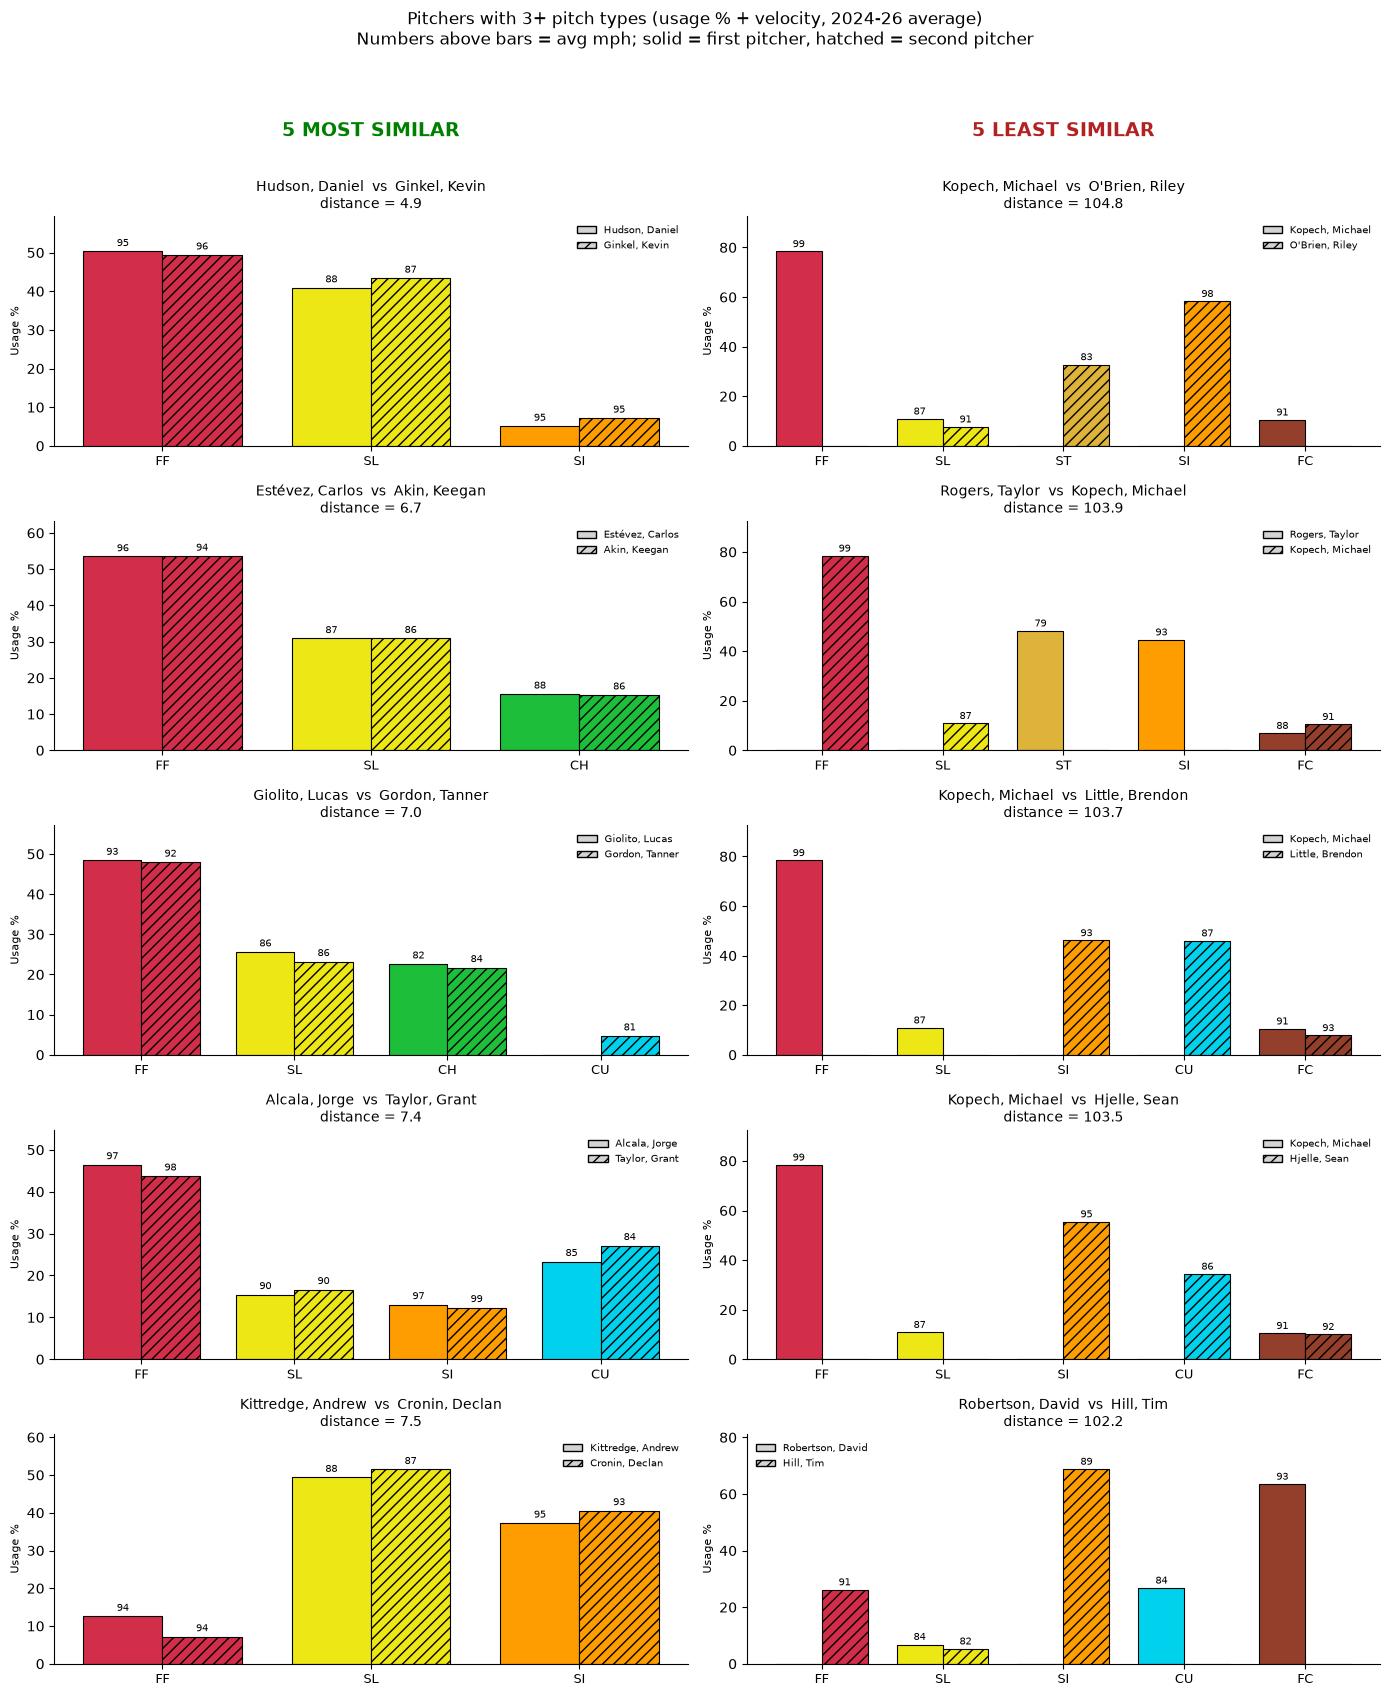

In [3]:
MIN_USAGE = 5.0      # a pitch only "counts" if it's thrown >= 5% of the time (averaged)
MIN_PITCH_TYPES = 3  # keep pitchers with at least this many counting pitch types

# 1) Filter to pitchers with 3+ pitch types

n_pitch_types = (usage_avg >= MIN_USAGE).sum(axis=1)
keep_idx = n_pitch_types[n_pitch_types >= MIN_PITCH_TYPES].index

usage_3p = usage_avg.loc[keep_idx]
speed_3p = speed_avg.loc[keep_idx]
print(f"{len(usage_3p)} of {len(usage_avg)} pitchers throw {MIN_PITCH_TYPES}+ pitch types "
      f"(>= {MIN_USAGE}% usage)")

# 2) Build usage + velocity vectors and compare
# Note: velocity z-scores are computed here among the filtered group only.
# Pass the full speed_avg stats instead if you want league-wide scaling.

combined_3p = build_combined_vectors(usage_3p, speed_3p)
pairs_3p = pairwise_distances(combined_3p)

most_similar_3p = pairs_3p.head(5)
least_similar_3p = pairs_3p.tail(5).iloc[::-1]

print("\nMost similar (3+ pitch types):\n",
      most_similar_3p[['pitcher_a', 'pitcher_b', 'distance']])
print("\nLeast similar (3+ pitch types):\n",
      least_similar_3p[['pitcher_a', 'pitcher_b', 'distance']])

# 3) Visualize 

fig = plot_top_pairs(
    most_similar_3p, least_similar_3p, usage_3p, speed_3p,
    title=f'Pitchers with {MIN_PITCH_TYPES}+ pitch types '
          f'(usage % + velocity, 2024-26 average)')
plt.show()

361 of 489 pitchers throw 4+ pitch types (>= 5.0% usage)

Most similar (4+ pitch types):
            pitcher_a           pitcher_b  distance
0      Alcala, Jorge       Taylor, Grant  7.385888
1       Fedde, Erick        Topa, Justin  7.990465
2      deGrom, Jacob        Jones, Jared  8.612028
3       Ragans, Cole  Rodriguez, Grayson  8.673118
4  Verlander, Justin       Knack, Landon  8.692200

Least similar (4+ pitch types):
                  pitcher_a           pitcher_b   distance
64979            Blach, Ty  Misiorowski, Jacob  93.810638
64978       Bruihl, Justin  Misiorowski, Jacob  91.480469
64977        Hurter, Brant  Misiorowski, Jacob  90.733043
64976        Chavez, Jesse  Misiorowski, Jacob  88.145582
64975  Bernardino, Brennan  Misiorowski, Jacob  87.317699


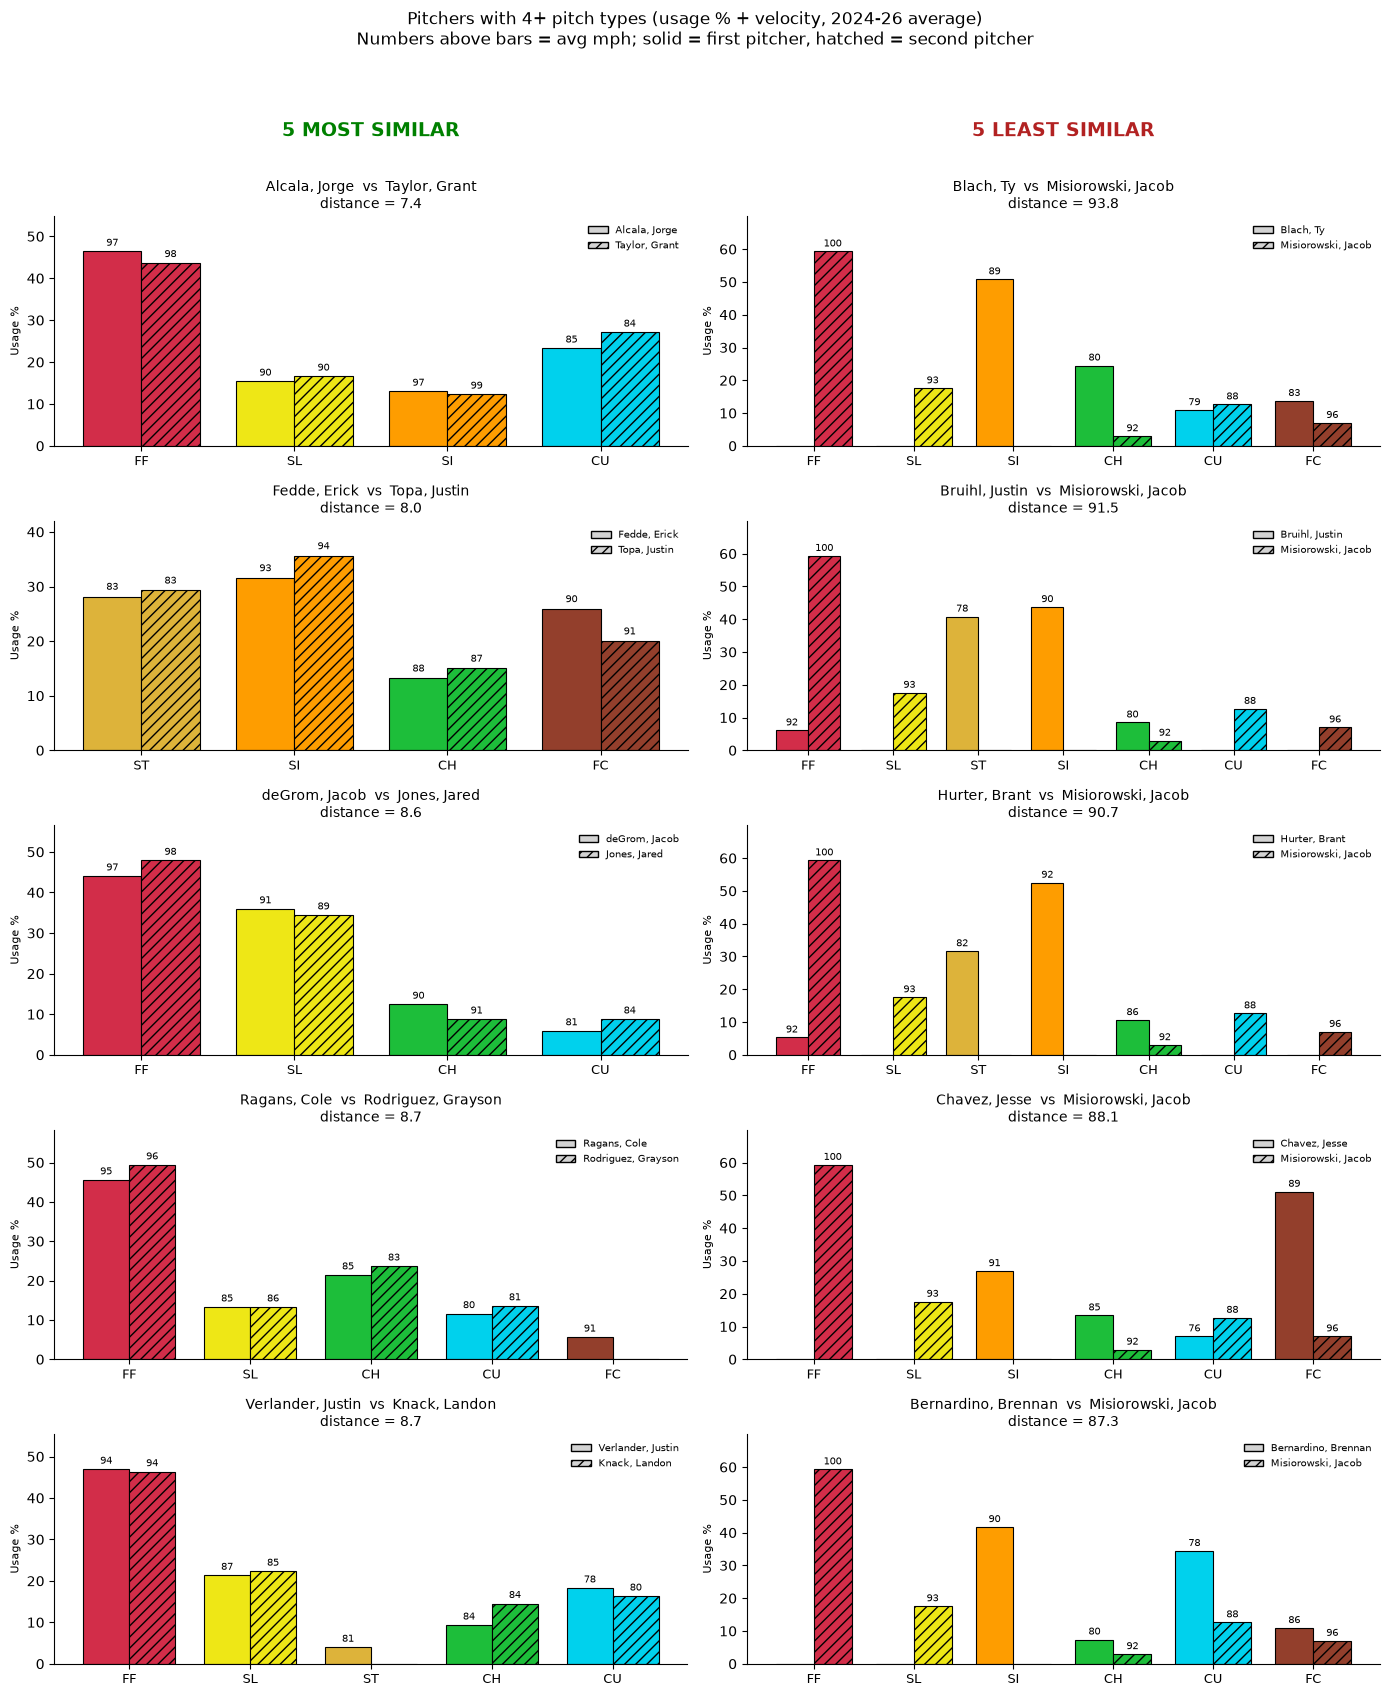

In [4]:
MIN_USAGE = 5.0      # a pitch only "counts" if it's thrown >= 5% of the time (averaged)
MIN_PITCH_TYPES = 4  # keep pitchers with at least this many counting pitch types


n_pitch_types = (usage_avg >= MIN_USAGE).sum(axis=1)
keep_idx = n_pitch_types[n_pitch_types >= MIN_PITCH_TYPES].index

usage_4p = usage_avg.loc[keep_idx]
speed_4p = speed_avg.loc[keep_idx]
print(f"{len(usage_4p)} of {len(usage_avg)} pitchers throw {MIN_PITCH_TYPES}+ pitch types "
      f"(>= {MIN_USAGE}% usage)")


combined_4p = build_combined_vectors(usage_4p, speed_4p)
pairs_4p = pairwise_distances(combined_4p)

most_similar_4p = pairs_4p.head(5)
least_similar_4p = pairs_4p.tail(5).iloc[::-1]

print("\nMost similar (4+ pitch types):\n",
      most_similar_4p[['pitcher_a', 'pitcher_b', 'distance']])
print("\nLeast similar (4+ pitch types):\n",
      least_similar_4p[['pitcher_a', 'pitcher_b', 'distance']])

fig = plot_top_pairs(
    most_similar_4p, least_similar_4p, usage_4p, speed_4p,
    title=f'Pitchers with {MIN_PITCH_TYPES}+ pitch types '
          f'(usage % + velocity, 2024-26 average)')
plt.show()

# Creating a multi-layer network

Each row of the dataset is a type of pitch thrown by a specific pitcher. This means we should be able to predict the type of pitch based on the parameters given. There are 53 columns, but not all of them may be parameters that we need.

First, let's pick which columns should be part of our inputs and outputs. We want to use each pitch's characteristics to predict what type of pitch it is. Columns that describe the pitcher, team, year, or summary stats like the number of pitches that pitcher threw won't be useful. Instead, we want to keep columns that have numerical data that is descriptive of the class of pitch that is thrown.

The columns that fit the criteria are columns like pitch usage, avg_speed, break (ball movement in the air), pitch run value, whiff percent, strike percent, put away percent, and estimated batting average, slugging percentage, on base percentage, and hard hit percentage. These columns are descriptive of the pitch categories themselves, and while each pitcher throws a pitch a little differently, the odds are that one pitcher's fastball moves more like another pitcher's fastball rather than another pitcher's curveball.

In [5]:
desired_cols = baseball.columns[8:14].tolist() + baseball.columns[46:53].tolist()
print(desired_cols)

['pitch_usage', 'avg_speed', 'pitcher_break_x', 'pitcher_break_z_induced', 'run_value_per_100', 'run_value', 'whiff_percent', 'k_percent', 'put_away', 'est_ba', 'est_slg', 'est_woba', 'hard_hit_percent']


In [6]:
input_columns = desired_cols # Which columns are providing numeric data that can be used to predict the output?
output_column = 'pitch_name' #Which column represents our desired output?

We can use these columns to define input and output data arrays:

In [7]:
input = np.array(baseball[input_columns])
output = np.array(baseball[output_column])

Next, we restructured our outputs using one-hot encoding. In order to one-hot encode our outputs, we'll be going from a single output variable to a vector of probabilities representing how probable each of these pitches are. Instead of the model predicting a pitch is 63% fastball, 35% sinker, and 2% changeup, it drives the highest likelihood pitch to 1 and the rest take on zero. One-hot encoding is a method of converting categorical data into binary data to make it compatible with the back-prop network.

In [8]:
def one_hot(i):
  one_hot_encoded = np.array([0]*11)
  one_hot_encoded[i-1]=1
  return np.array(one_hot_encoded)

In [9]:
# Map each unique pitch name string to a numeric index (1 to 11) for one_hot encoding
unique_pitches = list(np.unique(output))
pitch_to_index = {name: idx + 1 for idx, name in enumerate(unique_pitches)}

# Convert each pitch name to its index and one-hot encode it
output = np.array([one_hot(pitch_to_index[c]) for c in output])

In [10]:
class PrintEveryNEpochs(callbacks.Callback):

  def __init__(self, n=25):
    super().__init__()
    self.n = n

  def on_epoch_end(self, epoch, logs=None):
    # 'epoch' is 0-indexed, so add 1 for human-readable counting
    current_epoch = epoch + 1
    if current_epoch % self.n == 0 or current_epoch == 1:
      # Format all available metrics (loss, val_loss, accuracy, etc.)
      metrics_str = " - ".join([f"{k}: {v:.4f}" for k, v in logs.items()])
      print(f"Epoch {current_epoch}/100 - {metrics_str}")

In [11]:
#This line creates the model, and lets us know that information only flows forward; there's no recurrence
model = models.Sequential()
#This line creates a densely-connected layer from the inputs to a hidden layer with 20 nodes
model.add(layers.Dense(20, activation='relu'))
#This line creates a densely-connected layer from the first hidden layer to a second hidden layer with 5 nodes
model.add(layers.Dense(5, activation='relu'))
#This line creates a densely-connected layer from the second hidden layer to the output layer
model.add(layers.Dense(11, activation = 'softmax'))

In [12]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.CategoricalCrossentropy(),
              metrics=['accuracy'])

Now let's train the model!

In [13]:
history = model.fit(input, output, epochs = 100, verbose=0,
                   callbacks=[PrintEveryNEpochs(n=10)])

Epoch 1/100 - accuracy: 0.2665 - loss: 5.1074
Epoch 10/100 - accuracy: 0.7112 - loss: 0.8753
Epoch 20/100 - accuracy: 0.7849 - loss: 0.6223
Epoch 30/100 - accuracy: 0.7982 - loss: 0.5705
Epoch 40/100 - accuracy: 0.8064 - loss: 0.5420
Epoch 50/100 - accuracy: 0.8151 - loss: 0.5230
Epoch 60/100 - accuracy: 0.8159 - loss: 0.5097
Epoch 70/100 - accuracy: 0.8186 - loss: 0.5017
Epoch 80/100 - accuracy: 0.8202 - loss: 0.4963
Epoch 90/100 - accuracy: 0.8219 - loss: 0.4926
Epoch 100/100 - accuracy: 0.8243 - loss: 0.4886


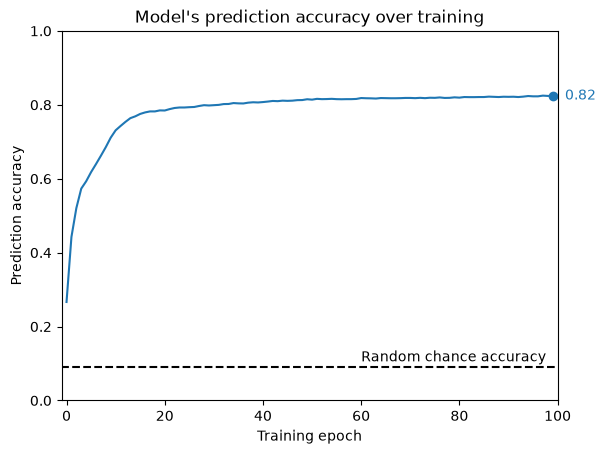

In [14]:
#@title Plot accuracy
#plt.figure(figsize=(12,7))
plt.plot(history.history['accuracy'])
plt.xlabel('Training epoch')
plt.ylabel('Prediction accuracy')
plt.title('Model\'s prediction accuracy over training')
plt.hlines(y=1/11, xmin=-10, xmax=110, linestyles='dashed', color='k')
plt.ylim(0,1)
plt.xlim(-1,100)
plt.text(x=60, y=(1/11)+0.015, s="Random chance accuracy",  color='k')
max_accuracy = history.history['accuracy'][-1]
plt.scatter([99], [max_accuracy], color='tab:blue')
plt.text(x=101.5, y = max_accuracy-0.01, s='{:.2f}'.format(max_accuracy), color='tab:blue')
plt.show()


The model can accurately predict pitches ~81% of the time based on the selected parameters. Let's try it again, this time adding an extra hidden layer, increasing the number of nodes for some of the hidden layers, and training for 1000 epochs instead of just 100.

In [15]:
class PrintEveryNEpochs(callbacks.Callback):

  def __init__(self, n=25):
    super().__init__()
    self.n = n

  def on_epoch_end(self, epoch, logs=None):
    # 'epoch' is 0-indexed, so add 1 for human-readable counting
    current_epoch = epoch + 1
    if current_epoch % self.n == 0 or current_epoch == 1:
      # Format all available metrics (loss, val_loss, accuracy, etc.)
      metrics_str = " - ".join([f"{k}: {v:.4f}" for k, v in logs.items()])
      print(f"Epoch {current_epoch}/1000 - {metrics_str}")

#This line creates the model, and lets us know that information only flows forward; there's no recurrence
model3 = models.Sequential()
#This line creates a densely-connected layer from the inputs to a hidden layer with 20 nodes
model3.add(layers.Dense(20, activation='relu'))
#This line creates a densely-connected layer from the first hidden layer to a second hidden layer with 12 nodes
model3.add(layers.Dense(12, activation='relu'))
#This line creates a densely-connected layer from the second hidden layer to a third hidden layer with 29 nodes
model3.add(layers.Dense(29, activation='relu'))
#This line creates a densely-connected layer from the third hidden layer to the output layer
model3.add(layers.Dense(11, activation = 'softmax'))

In [16]:
model3.compile(optimizer='adam',
              loss=tf.keras.losses.CategoricalCrossentropy(),
              metrics=['accuracy'])

history3 = model3.fit(input, output, epochs = 1000,
                     verbose=0,
    callbacks=[PrintEveryNEpochs(n=25)],
) #1000 epochs instead of 100

Epoch 1/1000 - accuracy: 0.3253 - loss: 2.2210
Epoch 25/1000 - accuracy: 0.8080 - loss: 0.5247
Epoch 50/1000 - accuracy: 0.8205 - loss: 0.4904
Epoch 75/1000 - accuracy: 0.8284 - loss: 0.4658
Epoch 100/1000 - accuracy: 0.8357 - loss: 0.4460
Epoch 125/1000 - accuracy: 0.8414 - loss: 0.4323
Epoch 150/1000 - accuracy: 0.8436 - loss: 0.4179
Epoch 175/1000 - accuracy: 0.8531 - loss: 0.4028
Epoch 200/1000 - accuracy: 0.8556 - loss: 0.3950
Epoch 225/1000 - accuracy: 0.8597 - loss: 0.3848
Epoch 250/1000 - accuracy: 0.8610 - loss: 0.3830
Epoch 275/1000 - accuracy: 0.8569 - loss: 0.3832
Epoch 300/1000 - accuracy: 0.8627 - loss: 0.3733
Epoch 325/1000 - accuracy: 0.8629 - loss: 0.3715
Epoch 350/1000 - accuracy: 0.8676 - loss: 0.3605
Epoch 375/1000 - accuracy: 0.8686 - loss: 0.3544
Epoch 400/1000 - accuracy: 0.8610 - loss: 0.3651
Epoch 425/1000 - accuracy: 0.8646 - loss: 0.3588
Epoch 450/1000 - accuracy: 0.8618 - loss: 0.3474
Epoch 475/1000 - accuracy: 0.8692 - loss: 0.3491
Epoch 500/1000 - accuracy

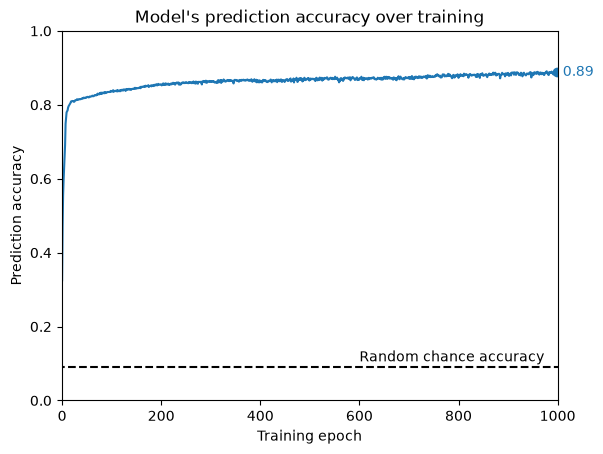

In [17]:
plt.plot(history3.history['accuracy'])
plt.xlabel('Training epoch')
plt.ylabel('Prediction accuracy')
plt.title('Model\'s prediction accuracy over training')
plt.hlines(y=1/11, xmin=-10, xmax=1010, linestyles='dashed', color='k')
plt.ylim(0,1)
plt.xlim(-1,1000)
plt.text(x=600, y=(1/11)+0.015, s="Random chance accuracy",  color='k')
max_accuracy = history3.history['accuracy'][-1]
plt.scatter([999], [max_accuracy], color='tab:blue')
plt.text(x=1010.5, y = max_accuracy-0.01, s='{:.2f}'.format(max_accuracy), color='tab:blue')
plt.show()

With the increased number of layers, nodes, and training time, the model is able to accurately label the type of pitch that was thrown almost 90% of the time. This is far better than a 9% chance at guessing what type of pitch was thrown if you just picked a category at random. An application for this model would be figuring out the pitch spread that an opposing pitcher might throw in a 7 game playoff series if you only have a limited amount of pitch data from that pitcher.


One explanation for the loss is that pitch types are being confused for one another based on the movement of the ball. For example, in Dylan Cease's 2026 season, his fastball, changeup, and sinker have overlap on the pitch chart because of their similar vertical and horizontal break. This is a relatively common occurance. It's also not farfetched to think that different pitches could be thrown at similar velocities, further muddying the waters.

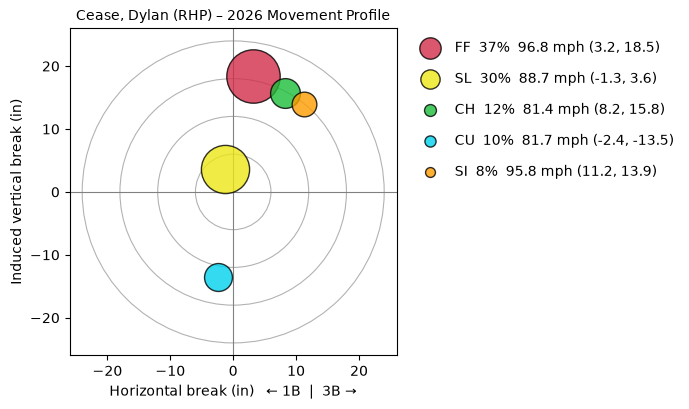

In [18]:
movement_plot(baseball, 'Cease, Dylan', 2026)
plt.show()

Overall, the model does a good job of predicting pitches, but the variance in levels of break and the raw volume of pitchers undoubtedly muddies the waters. Additionally, pitchers often have their own levels of spin for any given pitch. Where one pitcher's sweeper lives, another pitcher's slider could overlap, for instance. We predict that the outliers of any given pitch category tend to reduce the accuracy of the model.

For future direction, perhaps a model could similarly predict who *pitched* a game based on the pitch arsenal thrown (the breakdown of percent of which pitch is thrown, along with the pitch velocities, break, etc.). Unfortunately, the dataset doesn't have individual game data, instead working with season averages, so we're unable to test it.